# Day 2-3 Lab, Part 1: scikit-learn Style ML Basics

**NIAI AI/ML Program · Module 3-4 · Trainer: Anique Atique Alam**

**How this notebook works**
- Cells marked `# TODO` are yours to complete. Cells with `assert` check your work.
- Sections show which lecture part they need: **II** (ML foundations), **III** (linear regression), **IV** (logistic regression).
- All datasets are bundled with scikit-learn, so no network is needed.
- Kernel: `niai-ml` (select it in the top right of JupyterLab).

| Section | Topic | Needs | Time |
|---|---|---|---|
| 1 | The estimator API | II | 15 min |
| 2 | Metrics, baselines, cross-validation | II | 15 min |
| 3 | Pipelines and leakage | II | 10 min |
| 4 | Build your own estimator (gradient descent) | III | 25 min |
| 5 | Polynomial regression and Ridge | III | 15 min |
| 6 | Logistic regression | IV | 20 min |
| 7 | Checkpoint questions | | 5 min |

In [1]:
import time
import numpy as np
from numpy import array
# print(numpy.__file__)
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_breast_cancer, load_diabetes, load_iris
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (confusion_matrix, f1_score, mean_absolute_error,
                             mean_squared_error, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GridSearchCV, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (6, 3.5)

## 1. The estimator API (Part II)

Every scikit-learn model follows the same contract:

| Method | Meaning |
|---|---|
| `fit(X, y)` | learn from the training data |
| `predict(X)` | produce predictions |
| `score(X, y)` | default quality metric (R² for regressors, accuracy for classifiers) |
| `transform(X)` | (preprocessors) convert data using what `fit` learned |

Learned values end with an underscore: `coef_`, `intercept_`.

We start with the diabetes dataset: 10 numeric features, predict disease progression.

In [2]:
X, y = load_diabetes(return_X_y=True, as_frame=True)
print(X.shape, y.shape)
X.head()

(442, 10) (442,)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [3]:
# TODO: split into 80% train / 20% test, using random_state=RANDOM_STATE

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)


In [4]:
# TODO 1: create a LinearRegression model
model = LinearRegression()

# TODO 2: train it on the training data
model.fit(X_train, y_train)

# TODO 3: predict on the test data
y_pred = model.predict(X_test)

In [5]:
assert X_train.shape[0] == 353
assert model.coef_.shape == (10,)
assert y_pred.shape == y_test.shape
print("R^2 on test:", round(model.score(X_test, y_test), 3))
pd.Series(model.coef_, index=X.columns).sort_values()  #index=X.columns	labels each weight with its feature name

#Sign → direction of the effect: positive coeff means increasing that feature increases the prediction (holding others constant); negative means the opposite.

R^2 on test: 0.453


s1    -931.488846
sex   -241.964362
age     37.904021
s6      48.670657
s3     163.419983
s4     275.317902
bp     347.703844
s2     518.062277
bmi    542.428759
s5     736.198859
dtype: float64

model.score(X_test, y_test) computes the coefficient of determination R² on the test set.

R² = 1 → perfect predictions
R² = 0 → model is no better than predicting the mean
R² < 0 → model is worse than the mean baseline

This is the key evaluation metric — it tells you how much variance in y_test the model explains on unseen data. High train R² but low test R² would signal overfitting.
Note: score() on a regressor returns R² by default (not accuracy).

• Correlation (\(r\)):
 Represents the Pearson correlation coefficient. It scales tightly from -1 to +1. It tells you whether two variables move together, move in opposite directions, or have no linear relationship.
     Direction	Shows direction (positive or negative sign).
     Variables	Symmetric (X to Y is the same as Y to X).

• \(R^{2}\): 
Represents the coefficient of determination. It scales from 0 to 1 (or 0% to 100%) in simple models. It quantifies how much of the variance in a dependent variable is accounted for by your independent variable(s).
	 Directionless (squaring removes negative signs).
	 Asymmetric (Distinguishes predictors from outcomes).


 Use \(R^{2}\) 
 when you have established a direction of cause/effect and want to evaluate predictive accuracy.

• Evaluating Model Fit: Checking if a real estate algorithm using square footage to predict house prices explains enough variance to be useful.
• Index & Portfolio Tracking: Determining how much a mutual fund's returns are driven by the overall market index (e.g., an \(R^{2}\) of 0.95 means 95% of the fund's movements are explained by the index).
• Scientific Experiments: Evaluating how much the variation in plant growth rate is directly explained by the precise dosage of fertilizer applied.



When to Use Correlation (\(r\))

Use correlation when you want a quick diagnostic tool to find basic associations without making predictions.
• Exploratory Data Analysis: Screening a medical dataset to see if blood pressure and cholesterol levels tend to rise together.
• Feature Selection: Checking a dataset before building a machine learning model to find which raw features track closely with the target variable.
• Finance & Diversification: Finding assets with a negative or zero correlation (e.g., gold vs. tech stocks) to build a resilient, balanced portfolio.

## 2. Metrics, baselines and cross-validation (Part II)

A score means nothing without a **baseline**. First compute the three regression metrics yourself, then compare to a model that always predicts the training mean.

In [6]:
# TODO: compute by hand with numpy (no sklearn.metrics)
#   MAE  = mean(|error|)      RMSE = sqrt(mean(error^2))
#   R2   = 1 - sum(error^2) / sum((y - mean(y))^2)
err = y_test - y_pred
mae = np.mean(np.abs(err))
rmse = np.sqrt(np.mean(err**2))
r2 = 1- np.sum(err**2) / np.sum((y_test-np.mean(y_test))**2)

In [7]:
assert np.isclose(mae, mean_absolute_error(y_test, y_pred))
assert np.isclose(rmse, np.sqrt(mean_squared_error(y_test, y_pred)))
assert np.isclose(r2, model.score(X_test, y_test))
print(f"MAE {mae:.1f}   RMSE {rmse:.1f}   R2 {r2:.3f}")

MAE 42.8   RMSE 53.9   R2 0.453


In [8]:
# TODO: baseline = DummyRegressor(strategy="mean"), fit on the training data
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

base_r2 = baseline.score(X_test, y_test)

In [9]:
assert base_r2 < 0.05, "a mean predictor should have R^2 near 0"
assert model.score(X_test, y_test) > base_r2
print(f"baseline R2 {base_r2:.3f}  vs  model R2 {model.score(X_test, y_test):.3f}")

baseline R2 -0.012  vs  model R2 0.453


One split can be lucky or unlucky. **Cross-validation** averages over several splits.

In [10]:
# TODO: 5-fold cross-validated R^2 for a fresh LinearRegression on the FULL X, y
scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")

In [11]:
assert len(scores) == 5
print("fold scores:", scores.round(3))
print(f"mean {scores.mean():.3f} +/- {scores.std():.3f}")

fold scores: [0.43  0.523 0.483 0.426 0.55 ]
mean 0.482 +/- 0.049


## 3. Pipelines and leakage (Part II)

Scalers and imputers **learn** statistics. If they learn them from the whole dataset, test information leaks into training. A `Pipeline` keeps preprocessing and model together so it is refit correctly each time.

In [12]:
Xc, yc = load_breast_cancer(return_X_y=True, as_frame=True)
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(
    Xc, yc, test_size=0.2, stratify=yc, random_state=RANDOM_STATE)

scaler_all = StandardScaler().fit(Xc)      # WRONG: has seen the test rows

# TODO: the RIGHT way: fit a scaler on the training rows only
scaler_train = StandardScaler().fit(Xc_tr)

In [13]:
leak_gap = np.abs(scaler_all.mean_ - scaler_train.mean_).max()
assert leak_gap > 0
print("largest difference in a learned mean:", round(leak_gap, 3))

#Compares the learned means of the two scalers (per feature) and takes the largest absolute difference across features. mean_ is the fitted per-feature mean stored on the scaler.

largest difference in a learned mean: 11.557


In [14]:
# TODO: build a pipeline: StandardScaler then LogisticRegression(max_iter=1000)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

pipe.fit(Xc_tr, yc_tr)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [15]:
assert isinstance(pipe.steps[0][1], StandardScaler)
assert pipe.score(Xc_te, yc_te) > 0.95
print("test accuracy:", round(pipe.score(Xc_te, yc_te), 3))

test accuracy: 0.982


Real tables mix numeric and categorical columns, with missing values. `ColumnTransformer` applies the right steps to the right columns, which is exactly what your `quakes` project does.

In [16]:
df_mixed = pd.DataFrame({
    "age":    [25, 32, np.nan, 41, 29, 55],
    "income": [40, 52, 61, np.nan, 45, 90],
    "city":   ["Lahore", "Karachi", "Lahore", np.nan, "Quetta", "Karachi"],
})

# TODO: numeric (age, income): median imputation, then StandardScaler
#       nominal (city): most-frequent imputation, then OneHotEncoder(handle_unknown="ignore", sparse_output=False)


numeric = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
nominal = make_pipeline(SimpleImputer(strategy="most_frequent"),
                        OneHotEncoder(handle_unknown="ignore", sparse_output=False))
prep = ColumnTransformer([
    ("num", numeric, ["age", "income"]),
    ("nom", nominal, ["city"]),
])

Xt = prep.fit_transform(df_mixed)

In [17]:
assert Xt.shape == (6, 5), f"expected 2 numeric + 3 city columns, got {Xt.shape}"
assert not np.isnan(Xt).any()
print(prep.get_feature_names_out())

['num__age' 'num__income' 'nom__city_Karachi' 'nom__city_Lahore'
 'nom__city_Quetta']


## 4. Build your own estimator: gradient descent (Part III)

Model: $\hat y = \mathbf{x}^\top \mathbf{w} + b$. Loss: $J = \frac{1}{2m}\sum_i (\hat y_i - y_i)^2$.

Gradients: $\frac{\partial J}{\partial w_j} = \frac{1}{m}\sum_i (\hat y_i - y_i)\,x_{ij}$ and $\frac{\partial J}{\partial b} = \frac{1}{m}\sum_i (\hat y_i - y_i)$.

Update: $w_j \leftarrow w_j - \alpha \,\partial J / \partial w_j$.

You will write the gradient twice (loops, then vectorized), check they agree, time them, and wrap the vectorized one in a scikit-learn style class.

In [18]:
rng = np.random.default_rng(RANDOM_STATE)
X_syn = rng.normal(size=(500, 3))   #feature matrix
w_true, b_true = np.array([2.0, -1.0, 0.5]), 3.0
y_syn = X_syn @ w_true + b_true + rng.normal(0, 0.5, 500)

In [19]:
def gradient_loop(X, y, w, b):
    """Gradient of J using plain Python loops. Returns (grad_w, grad_b)."""
    m, n = X.shape
    grad_w = np.zeros(n)
    grad_b = 0.0
    for i in range(m):  #rows  #every sample
        # TODO: prediction for sample i, using a loop over features j      
        #    predicted= b + w1 * (xi1) + w2 *(xi2) + wn * (xiN)
        
        pred = b
        for j in range(n):               #every feature 
            pred += X[i, j] * w[j]
        err = pred - y[i]
        # TODO: add this sample's contribution to grad_w[j] (every j) and to grad_b
        for j in range(n):
            grad_w[j] += err * X[i, j]                 # multiplies the error by the feature value, which corresponds to (predicted(yi) -actual (yi)) * (x[ij])
        grad_b += err
        
    return grad_w / m, grad_b / m

In [20]:
def gradient_vec(X, y, w, b):
    """Same gradient with NO Python loops. Returns (grad_w, grad_b)."""
    # TODO: err = X @ w + b - y ; grad_w = X.T @ err / m ; grad_b = err.mean()
    m = X.shape[0]      # m is the number of samples (rows in X). 
    err = X @ w + b - y
    grad_w = X.T @ err / m
    grad_b = err.mean()
    return grad_w, grad_b

In [21]:
w0, b0 = rng.normal(size=3), 1.0
gw_l, gb_l = gradient_loop(X_syn, y_syn, w0, b0)
gw_v, gb_v = gradient_vec(X_syn, y_syn, w0, b0)
assert np.allclose(gw_l, gw_v) and np.isclose(gb_l, gb_v), "loop and vectorized gradients differ"
print("gradients agree")

gradients agree


In [22]:
X_big, y_big = rng.normal(size=(20000, 5)), rng.normal(size=20000)
w5 = np.zeros(5)

t0 = time.perf_counter(); gradient_loop(X_big, y_big, w5, 0.0); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); gradient_vec(X_big, y_big, w5, 0.0);  t_vec = time.perf_counter() - t0
print(f"loop {t_loop*1000:.1f} ms   vectorized {t_vec*1000:.2f} ms   speedup x{t_loop/t_vec:.0f}")
assert t_vec < t_loop

loop 373.1 ms   vectorized 1.66 ms   speedup x224


In [23]:
class GDLinearRegression(BaseEstimator, RegressorMixin):
    def __init__(self, lr=0.1, n_iter=1000):
        self.lr = lr
        self.n_iter = n_iter

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        w, b = np.zeros(X.shape[1]), 0.0
        self.loss_history_ = []
        for _ in range(self.n_iter):
            # TODO 1: append the current loss (1/2m) * sum(err**2) to loss_history_
            
            err = X @ w + b - y
            self.loss_history_.append(np.sum(err ** 2) / (2 * len(y)))  #loss function
            
            # TODO 2: get gradients from gradient_vec, then update w and b
            
            grad_w, grad_b = gradient_vec(X, y, w, b)
            w = w - self.lr * grad_w
            b = b - self.lr * grad_b
        self.coef_, self.intercept_ = w, b
        return self
          
  

    def predict(self, X):
        # TODO: X @ coef_ + intercept_
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

In [24]:
gd = GDLinearRegression(lr=0.1, n_iter=1000).fit(X_syn, y_syn)
ref = LinearRegression().fit(X_syn, y_syn)
assert gd.loss_history_[-1] < gd.loss_history_[0]    

#What it checks: It looks at the loss_history_ list (which your class should be recording at every iteration). It asserts that the final loss is strictly less than the initial loss.
assert np.allclose(gd.coef_, ref.coef_, atol=0.02), "should match the closed-form solution"
print("GD coef:", gd.coef_.round(3), " sklearn coef:", ref.coef_.round(3))

GD coef: [ 1.956 -0.989  0.52 ]  sklearn coef: [ 1.956 -0.989  0.52 ]


**Learning rate.** Fit with three learning rates and watch the loss curve. One is too small, one is right, one is too large.

In [25]:
learning_rates = [0.001, 0.1, 2.5]
histories = {}
for lr in learning_rates:
    # TODO: fit GDLinearRegression(lr=lr, n_iter=60) on X_syn, y_syn and store loss_history_ in histories[lr]
    histories[lr] = GDLinearRegression(lr=lr, n_iter=60).fit(X_syn, y_syn).loss_history_    

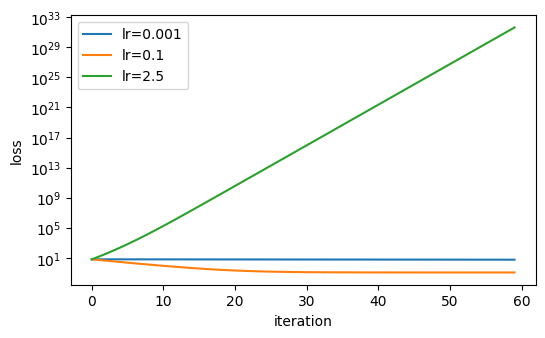

In [26]:
for lr, h in histories.items():
    plt.plot(h, label=f"lr={lr}")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("loss"); plt.legend(); plt.show()
assert histories[0.1][-1] < histories[0.001][-1]
assert histories[2.5][-1] > histories[2.5][0], "lr=2.5 should diverge"

**Feature scaling.** The same algorithm on features with very different scales:

In [27]:
scales = np.array([1.0, 50.0, 0.1])
X_raw = X_syn * scales
y_raw = X_raw @ np.array([2.0, -0.04, 10.0]) + 3.0 + rng.normal(0, 0.5, 500)
X_scaled = StandardScaler().fit_transform(X_raw)

# TODO: fit on the UNSCALED data with lr=1e-4, n_iter=500 (a larger lr would blow up the big feature)
#       and on the SCALED data with lr=0.1, n_iter=500. Keep the fitted models.


gd_raw    = GDLinearRegression(lr=1e-4, n_iter=500).fit(X_raw, y_raw)
gd_scaled = GDLinearRegression(lr=0.1,  n_iter=500).fit(X_scaled, y_raw)

In [28]:
print(f"final loss unscaled {gd_raw.loss_history_[-1]:.3f}   scaled {gd_scaled.loss_history_[-1]:.3f}")
assert gd_scaled.loss_history_[-1] < gd_raw.loss_history_[-1] / 10

final loss unscaled 6.530   scaled 0.130


## 5. Polynomial regression and Ridge (Part III)

A polynomial model is still *linear in the weights*: expand the features ($x, x^2, x^3, \dots$), then fit a linear model. The degree controls flexibility.

In [29]:
rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 2 * np.pi, 60))
y_sin = np.sin(x) + rng.normal(0, 0.3, 60)
Xp = x.reshape(-1, 1)
Xp_tr, Xp_val, yp_tr, yp_val = train_test_split(Xp, y_sin, test_size=0.3, random_state=RANDOM_STATE)

In [30]:
degrees = range(1, 13)
train_err, val_err = [], []
for d in degrees:
    # TODO: pipeline PolynomialFeatures(d, include_bias=False) -> StandardScaler -> LinearRegression
    model_d = make_pipeline(PolynomialFeatures(d, include_bias=False),
                        StandardScaler(),
                        LinearRegression())
    
    
    model_d.fit(Xp_tr, yp_tr)
    train_err.append(mean_squared_error(yp_tr, model_d.predict(Xp_tr)))
    val_err.append(mean_squared_error(yp_val, model_d.predict(Xp_val)))
best_degree = degrees[int(np.argmin(val_err))]

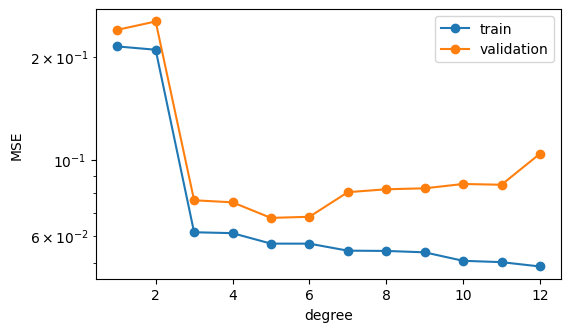

best degree on validation: 5


In [31]:
plt.plot(list(degrees), train_err, "o-", label="train")
plt.plot(list(degrees), val_err, "o-", label="validation")
plt.yscale("log"); plt.xlabel("degree"); plt.ylabel("MSE"); plt.legend(); plt.show()
assert train_err[-1] < train_err[0]
assert 2 <= best_degree <= 9
print("best degree on validation:", best_degree)

**Regularisation.** At degree 12 the plain model chases noise with huge weights. Ridge penalises large weights.

In [32]:
def poly_model(d, est):
    return make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), est)

plain = poly_model(12, LinearRegression()).fit(Xp_tr, yp_tr)


# TODO: ridge = the same degree-12 model with Ridge(alpha=1.0), fit on the same data
ridge = poly_model(12, Ridge(alpha=1.0)).fit(Xp_tr, yp_tr)



for a in [0.001, 0.01, 0.1, 1]:
    r = poly_model(12, Ridge(alpha=a)).fit(Xp_tr, yp_tr)
    print(a, round(mean_squared_error(yp_val, r.predict(Xp_val)), 4))
# the alpha with the lowest printed MSE is your answer

0.001 0.0666
0.01 0.0709
0.1 0.1015
1 0.1626


In [33]:
norm_plain = np.linalg.norm(plain[-1].coef_)
norm_ridge = np.linalg.norm(ridge[-1].coef_)
print(f"weight norm  plain {norm_plain:.1f}   ridge {norm_ridge:.1f}")
print(f"validation MSE plain {mean_squared_error(yp_val, plain.predict(Xp_val)):.3f}   "
      f"ridge {mean_squared_error(yp_val, ridge.predict(Xp_val)):.3f}")
assert norm_ridge < norm_plain

weight norm  plain 9449802.2   ridge 0.8
validation MSE plain 0.104   ridge 0.163


**Stretch:** Ridge with `alpha=1.0` may over-smooth. Try `alpha` in `[0.001, 0.01, 0.1, 1]` and report which one gives the lowest validation MSE. Regularisation strength is a hyperparameter you tune, not a constant.

## 6. Logistic regression (Part IV)

Breast cancer data. We treat **malignant as the positive class** (1), because missing a malignant case is the costly error.

In [34]:
yb = (yc == 0).astype(int)          # 1 = malignant
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    Xc, yb, test_size=0.2, stratify=yb, random_state=RANDOM_STATE)



# TODO: pipeline StandardScaler -> LogisticRegression(max_iter=1000); fit on the training data
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
clf.fit(Xb_tr, yb_tr)

# TODO: probability of the positive class for the test rows
proba = clf.predict_proba(Xb_te)[:, 1]


In [35]:
assert proba.shape == (len(Xb_te),)
auc = roc_auc_score(yb_te, proba)
assert auc > 0.95
print("ROC-AUC:", round(auc, 4))

ROC-AUC: 0.996


In [36]:
pred = (proba >= 0.5).astype(int)
# TODO: confusion matrix, precision, recall and F1 for `pred` (use sklearn.metrics)


cm        = confusion_matrix(yb_te, pred)
precision = precision_score(yb_te, pred)
recall    = recall_score(yb_te, pred)
f1        = f1_score(yb_te, pred)

In [37]:
assert cm.shape == (2, 2)
print(cm)
print(f"precision {precision:.3f}   recall {recall:.3f}   F1 {f1:.3f}")

[[71  1]
 [ 3 39]]
precision 0.975   recall 0.929   F1 0.951


**Threshold sweep.** 0.5 is a default, not a law. Lower thresholds catch more malignant cases and raise false alarms.

In [38]:
rows = []
for t in np.arange(0.1, 0.95, 0.1):
    # TODO: predictions at threshold t, then append {"threshold", "precision", "recall"} to rows
    p_t = (proba >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(yb_te, p_t, zero_division=0),
                 "recall": recall_score(yb_te, p_t)})    
    
    
    
table = pd.DataFrame(rows).round(3)
table

,threshold,precision,recall
0,0.1,0.891,0.976
1,0.2,0.911,0.976
2,0.3,0.976,0.976
3,0.4,0.976,0.952
4,0.5,0.975,0.929
5,0.6,1.000,0.905
6,0.7,1.000,0.905
7,0.8,1.000,0.857
8,0.9,1.000,0.786


In [39]:
# TODO: the HIGHEST threshold whose recall is still >= 0.95
#chosen_threshold = ...
chosen_threshold = max(r["threshold"] for r in rows if r["recall"] >= 0.95)



In [40]:
p = (proba >= chosen_threshold).astype(int)
assert recall_score(yb_te, p) >= 0.95
print("chosen threshold:", chosen_threshold)


chosen threshold: 0.4


**Multiclass.** Iris has three classes. `LogisticRegression` handles them directly (softmax).

In [41]:
Xi, yi = load_iris(return_X_y=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, stratify=yi, random_state=RANDOM_STATE)

# TODO: pipeline StandardScaler -> LogisticRegression(max_iter=1000), fit, then predict on the test set
iris_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
iris_clf.fit(Xi_tr, yi_tr)
iris_pred = iris_clf.predict(Xi_te)
###

iris_cm = confusion_matrix(yi_te, iris_pred)

In [42]:
assert iris_cm.shape == (3, 3)
assert (iris_pred == yi_te).mean() > 0.85
probs = iris_clf.predict_proba(Xi_te[:3])
assert np.allclose(probs.sum(axis=1), 1)
print(iris_cm); print(probs.round(3))

[[15  0  0]
 [ 0 14  1]
 [ 0  3 12]]
[[0.    0.101 0.899]
 [0.014 0.789 0.196]
 [0.004 0.62  0.376]]


**Tuning.** `C` is the *inverse* regularisation strength: small `C` means strong regularisation. Search over it with cross-validation. Note the pipeline keeps the scaler inside each fold.

In [43]:
param_grid = {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}
# TODO: GridSearchCV over a StandardScaler -> LogisticRegression pipeline with 5 folds, scoring="roc_auc"; fit on Xb_tr, yb_tr

search = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    param_grid, cv=5, scoring="roc_auc")
search.fit(Xb_tr, yb_tr)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('standardscaler', StandardScaler()),
                                       ('logisticregression',
                                        LogisticRegression(max_iter=1000))]),
             param_grid={'logisticregression__C': [0.01, 0.1, 1, 10, 100]},
             scoring='roc_auc')

In [44]:
assert search.best_score_ > 0.95
print(search.best_params_, round(search.best_score_, 4))

{'logisticregression__C': 10} 0.9958


## 7. Checkpoint questions

Answer in the cells below (2-3 sentences each).

1. In section 3, what exactly leaked when the scaler was fit on all rows, and why does that make a score untrustworthy?
2. In section 4, why does the loop version lose to the vectorized one, and what happened to the loss with `lr=2.5`?
3. In section 5, what happened to training and validation error as the degree grew, and what did Ridge change?

**Your answer to Q1:**

_(write here)_  Q1. The scaler’s learned statistics (each feature’s mean and standard deviation) leaked, because they were computed using the test rows too. The model then trains on data that was shaped by information from the test set. The test score no longer measures performance on truly unseen data, so it comes out optimistic and won’t hold up on new data.

**Your answer to Q2:**

 _(write here)_ Q2. The loop version runs the arithmetic one element at a time in interpreted Python. The vectorized version hands the whole computation to NumPy’s compiled code, which is far faster. With lr=2.5 the loss grew instead of shrinking, because each update overshoots the minimum by more than it corrects. The steps get larger every iteration, so gradient descent diverges.

**Your answer to Q3:**

 _(write here)_ Q3. As the degree grew, training error kept falling because the model fit the noise. Validation error fell at first, then rose once the model overfit. Ridge penalised large weights, so the degree-12 model had a much smaller weight norm and a smoother curve. That usually lowers validation error relative to the unregularised fit.